# W51 saturated-pixel recovery: v3 training set

2026-10-21

Follows `report_v2_training_set_20261020.ipynb`; decisions are in `discussion_20261021.ipynb` (question 16). Changes in `making_training_set.py` since v2:

| commit | change |
| --- | --- |
| `a7cab72` | `fluxerr` no longer multiplied by the star flux twice |
| `f49be8a` | HOT pixels are left out of the labels instead of dropping the whole source |
| `f49be8a` | new column `cal_value`: the pipeline value of each pixel, an alternative label |
| `f49be8a` | MIRI 4QPM pane pixels labelled like the imager field: pane data from `_bkgm` minus its background-match offset; new columns `in_4qpm` and `fqpm_quadrant` (0 = imager, 1-12 = pane quadrant) |
| `9f73745` | skip a source when HOT exclusion leaves no pixels (6 NIRCam filters crashed on this and were rerun) |

Output: `TRAIN_DIR/v3/`.

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table

REPO = '/blue/adamginsburg/t.yoo/w51_sat_recover'
TRAIN_DIR = '/orange/adamginsburg/w51/TaehwaYoo/w51_sat_recover'
pd.set_option('display.width', 160)

def load(version):
    frames = []
    for fn in sorted(glob.glob(f'{TRAIN_DIR}/{version}/*_ml_training.fits')):
        t = Table.read(fn)
        if len(t) == 0:
            continue
        d = pd.DataFrame({k: np.asarray(t[k]).astype(float) for k in t.colnames})
        d['file'] = os.path.basename(fn)
        frames.append(d)
    d = pd.concat(frames, ignore_index=True)
    d['source_id'] = d['file'] + '|' + d['psf_star_flux'].round(4).astype(str)
    d['inst'] = np.where(d['instrument'] == 0, 'NIRCam', 'MIRI')
    d['psf_share'] = (d['flux'] - d['local_bkg']) / d['flux']
    return d

v3 = load('v3')
v2 = load('v2')
n_tables = len(glob.glob(f'{TRAIN_DIR}/v3/*_ml_training.fits'))
print(f'v3: {n_tables} tables, {len(v3):,} rows, {v3.source_id.nunique():,} sources')
print(f'v2: {len(v2):,} rows, {v2.source_id.nunique():,} sources')

v3: 480 tables, 1,342,784 rows, 33,376 sources
v2: 1,179,223 rows, 31,454 sources


## 1. Run summary and skipped sources

Skip reasons are counted from the job logs (one warning per skipped source). F140M, F162M, F182M, F187N, F210M and F405N come from the rerun after `9f73745`.

In [2]:
logs = sorted(glob.glob(f'{REPO}/script/making_training_set-*_4706569*.log') + glob.glob(f'{REPO}/script/making_training_set-*_4706570*.log')
              + glob.glob(f'{REPO}/script/making_training_set-*_4707805*.log') + glob.glob(f'{REPO}/script/making_training_set-*_4707806*.log'))
reasons = {'all pixels HOT': 'all saturated pixels are HOT', 'DEAD pixel': 'flagged as DEAD', 'area_ratio': 'larger than the model',
           'fit SNR': 'low SNR', 'faint model': 'pixels above threshold; skipping', 'PSF fit failed': 'PSF photometry failed'}
skip = {}
for lf in logs:
    F = re.search(r'making_training_set-(F\w+?)_', lf).group(1)
    txt = open(lf, errors='replace').read()
    row = {'candidates': len(re.findall(r'^Source \d+: center', txt, re.M))}
    row.update({k: txt.count(v) for k, v in reasons.items()})
    row['tracebacks'] = txt.count('Traceback')
    skip[F] = row
skip = pd.DataFrame(skip).T.sort_index()
skip['kept'] = skip['candidates'] - skip[list(reasons)].sum(axis=1)
skip.loc['all'] = skip.sum()
skip

,candidates,all pixels HOT,DEAD pixel,area_ratio,fit SNR,faint model,PSF fit failed,tracebacks,kept
F1000W,536,0,81,20,154,197,0,0,84
F1280W,775,0,76,16,165,420,2,0,96
F140M,6133,1174,86,5,122,807,0,0,3939
F162M,6855,1175,106,4,125,884,0,0,4561
F182M,7845,1175,129,9,85,1059,0,0,5388
F187N,2821,1176,60,8,78,905,0,0,594
F2100W,682,0,53,20,88,421,0,0,100
F210M,6437,1176,110,17,87,983,0,0,4064
F335M,7478,0,654,226,45,2305,0,0,4248
F360M,7020,0,649,187,41,1752,0,0,4391


In v2 the HOT check dropped 11,052 of 62,714 candidate sources; v3 drops only the sources whose saturated pixels are all HOT.

In [3]:
def counts(d):
    c = pd.crosstab(d.sat_level, d.inst).reindex(columns=['NIRCam', 'MIRI'], fill_value=0)
    c['sources'] = d.groupby('sat_level').source_id.nunique()
    return c

pd.concat({'v2': counts(v2), 'v3': counts(v3)}, axis=1)

v2                     v3               
inst       NIRCam   MIRI sources  NIRCam   MIRI sources
sat_level                                              
0.0         37474   9046    2091   47157   9046    2458
1.0        423704  10176    9231  501067  10203   10199
2.0        259404   8638   11296  279243   8907   12063
3.0        223644   9302   15726  250484   9543   16789
4.0        197835      0   19642  227134      0   20766

## 2. `fluxerr` after the fix

`fluxerr` is now PSF(pixel) x the error of the star's fitted flux, so (label - `local_bkg`) / `fluxerr` is the star's fit SNR, constant over its pixels. The pipeline keeps only stars with SNR > 1.

In [4]:
snr = ((v3.flux - v3.local_bkg) / v3.fluxerr).groupby(v3.source_id).median()
print('star SNR 5/16/50/84/95%:', np.round(np.nanpercentile(snr, [5, 16, 50, 84, 95]), 1), ' min', round(snr.min(), 2))
print('per-pixel fluxerr / label, median:', (v3.fluxerr / v3.flux).groupby(v3.inst).median().round(4).to_dict())

star SNR 5/16/50/84/95%: [  22.1   60.6  325.6 1585.4 2283.4]  min 1.03
per-pixel fluxerr / label, median: {'MIRI': 0.008, 'NIRCam': 0.0024}


## 3. 4QPM pane pixels

MIRI pane pixels now get PSF-fit labels. `cal_value` in a pane is the `_bkgm` value minus the exposure's background-match offset (the pane flux calibration of the `jwst_new_cal_claude` pipeline).

In [5]:
mi = v3[v3.inst == 'MIRI']
pane = pd.crosstab(mi.wavelength.astype(int).rename('filter (um x 100)'), mi.in_4qpm.astype(bool).rename('in_4qpm'))
pane['pane sources'] = mi[mi.in_4qpm > 0].groupby(mi.wavelength.astype(int)).source_id.nunique()
pane

in_4qpm,False,True,pane sources
filter (um x 100),,,
560,7274,0,NaN
770,5633,131,8.0
1000,5045,0,NaN
1280,7058,42,2.0
2100,12182,334,5.0


In [6]:
pd.crosstab(mi.sat_level, mi.in_4qpm.astype(bool).rename('in_4qpm'))

in_4qpm,False,True
sat_level,,
0.0,9046,0
1.0,10176,27
2.0,8644,263
3.0,9326,217


## 4. Label check against `cal_value`

As in the v2 report: at `sat_level` 2-4 the pipeline value comes from unsaturated groups and tests the PSF label. Rows with a finite, positive `cal_value` only; ratio = PSF label / `cal_value`.

In [7]:
v3['ratio'] = v3.flux / v3.cal_value
ok = np.isfinite(v3.ratio) & (v3.cal_value > 0) & v3.sat_level.between(2, 4)
out = lambda s: ((s < 0.67) | (s > 1.5)).mean()

def check(d, by):
    g = d.groupby(by, observed=True).ratio
    return pd.DataFrame({'rows': g.size(), '16%': g.quantile(0.16), 'median': g.median(), '84%': g.quantile(0.84),
                         'outside 0.67-1.5': g.apply(out)}).round(3)

c = v3[ok].copy()
c['region'] = np.where(c.in_4qpm > 0, 'MIRI pane', np.where(c.inst == 'MIRI', 'MIRI imager', 'NIRCam'))
c['psf_share > 0.75'] = c.psf_share > 0.75
check(c, ['region', 'psf_share > 0.75'])

rows    16%  median    84%  outside 0.67-1.5
region      psf_share > 0.75                                                
MIRI imager False              12127  0.429   0.698  0.952             0.458
            True                4004  0.696   0.960  1.254             0.200
MIRI pane   False                 53  0.568   0.650  0.780             0.585
            True                 424  0.767   0.942  1.105             0.021
NIRCam      False             273816  0.799   0.962  1.094             0.099
            True              468100  0.878   0.992  1.103             0.082

In [8]:
check(c, ['region', 'sat_level'])

rows    16%  median    84%  outside 0.67-1.5
region      sat_level                                                
MIRI imager 2.0          8040  0.436   0.739  1.053             0.438
            3.0          8091  0.500   0.774  1.026             0.350
MIRI pane   2.0           262  0.825   0.987  1.113             0.057
            3.0           215  0.701   0.798  1.020             0.116
NIRCam      2.0        273841  0.844   0.989  1.115             0.094
            3.0        245591  0.844   0.986  1.094             0.088
            4.0        222484  0.837   0.981  1.086             0.083

## 5. Label selection: `psf_share` > 0.75 (decision 1)

Fraction of rows kept, and the rows left per `sat_level`, for all levels (levels 0-1 have no `cal_value` check).

In [9]:
keep = v3.psf_share > 0.75
frac = v3.assign(k=keep).groupby(['inst', 'sat_level']).k.mean().unstack().round(2)
left = v3[keep].groupby(['inst', 'sat_level']).size().unstack()
pd.concat({'fraction kept': frac, 'rows left': left}, axis=0)

sat_level                  0.0        1.0        2.0        3.0        4.0
              inst                                                        
fraction kept MIRI        0.84       0.56       0.33       0.20        NaN
              NIRCam      0.97       0.79       0.69       0.61       0.57
rows left     MIRI     7593.00    5670.00    2980.00    1877.00        NaN
              NIRCam  45712.00  396402.00  193797.00  152962.00  129003.00

## 6. Does `area_ratio` still matter after the `psf_share` cut? (item 7)

Label / `cal_value` at `sat_level` 2-4, among rows with `psf_share` > 0.75, by the source's `area_ratio`. If the medians stay flat, the 8.0 threshold needs no tuning.

In [10]:
k = c[c['psf_share > 0.75']].copy()
k['area_ratio bin'] = pd.cut(k.area_ratio, [0, 1, 2, 4, 6, 8])
check(k, ['region', 'area_ratio bin'])

rows    16%  median    84%  outside 0.67-1.5
region      area_ratio bin                                                
MIRI imager (0, 1]            1326  0.764   0.946  1.077             0.090
            (1, 2]            1366  0.725   0.918  1.164             0.134
            (2, 4]            1008  0.299   0.976  1.296             0.401
            (4, 6]              59  1.202   1.449  1.688             0.441
            (6, 8]             245  1.140   1.384  1.585             0.273
MIRI pane   (0, 1]             412  0.769   0.948  1.106             0.019
            (2, 4]               8  0.720   0.822  0.866             0.125
            (4, 6]               4  0.700   0.765  0.846             0.000
NIRCam      (0, 1]          352037  0.866   0.992  1.114             0.093
            (1, 2]           62844  0.884   0.988  1.098             0.059
            (2, 4]           38887  0.919   0.991  1.065             0.037
            (4, 6]           10102  0.929   0.991  1.047             0.026
            (6, 8]            4230  0.950   0.995  1.050             0.022

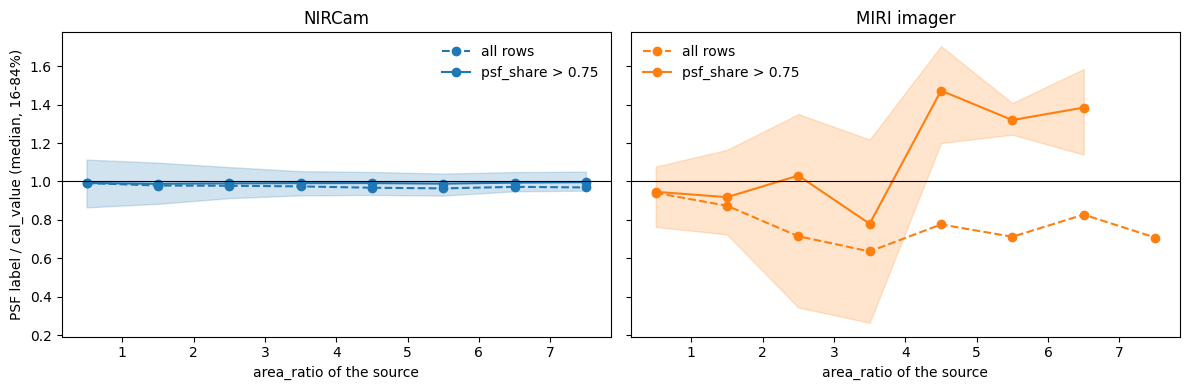

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (region, col) in zip(axes, [('NIRCam', 'C0'), ('MIRI imager', 'C1')]):
    h = c[c.region == region]
    for sel, ls, lab in [(np.ones(len(h), bool), '--', 'all rows'), (h['psf_share > 0.75'].to_numpy(), '-', 'psf_share > 0.75')]:
        g = h[sel].groupby(pd.cut(h[sel].area_ratio, [0, 1, 2, 3, 4, 5, 6, 7, 8]), observed=True).ratio
        mid = np.array([iv.mid for iv in g.median().index])
        ax.plot(mid, g.median(), ls, marker='o', color=col, label=lab)
        if lab != 'all rows':
            ax.fill_between(mid, g.quantile(0.16), g.quantile(0.84), color=col, alpha=0.2)
    ax.axhline(1, color='k', lw=0.8)
    ax.set_xlabel('area_ratio of the source')
    ax.set_title(region)
    ax.legend(frameon=False)
axes[0].set_ylabel('PSF label / cal_value (median, 16-84%)')
plt.tight_layout()

**Reading.**

* **Run.** All 15 filters, 480 tables, no tracebacks: 1,342,784 rows from 33,376 sources (v2: 1,179,223 from 31,454).
* **HOT pixels.** 5,922 candidate sources consist only of HOT pixels. In each NIRCam short-wave filter about 1,175 of them appear, the same in every filter, so they are bad-pixel clusters, not stars; they are still skipped. The other ~5,100 sources that the v2 HOT check dropped are now kept without their HOT pixels, mostly at NIRCam level 0-1 (NIRCam level 0: 37,474 -> 47,157 rows).
* **`fluxerr`** is now right: the star SNR runs 22-2,300 (5-95%), minimum 1.03 (the SNR > 1 cut), and the per-pixel error is 0.2% (NIRCam) and 0.8% (MIRI) of the label.
* **4QPM panes** add 534 MIRI rows from 15 sources (F770W 131, F1280W 42, F2100W 334; none at F560W and F1000W; none at level 0). Few pane sources survive, because most saturated pane pixels sit in regions larger than the 10,000-pixel edge limit or in bright emission where the faint-model check skips them. Where pane labels can be checked (levels 2-3, `psf_share` > 0.75, 424 rows), label / `cal_value` has a median of 0.94 and 2% of rows outside 0.67-1.5, as good as the imager field.
* **`psf_share` > 0.75** (decision 1) is a good cut. With it, label / `cal_value` has a median of 0.99 (NIRCam) and 0.96 (MIRI imager), and the share of rows outside 0.67-1.5 drops for MIRI from 46% to 20%. It keeps 97 / 79 / 69 / 61 / 57% of NIRCam rows at levels 0-4 and 84 / 56 / 33 / 20% of MIRI rows at levels 0-3, leaving 45,712 NIRCam and 7,593 MIRI level-0 rows.
* **`area_ratio` (item 7).** After the `psf_share` cut it no longer matters for NIRCam (medians 0.99 at every ratio, outliers 2-9%). For MIRI it still does: ratios 0-2 give medians of 0.92-0.95, ratios 2-4 a median of 0.98 but 40% outliers, and ratios 4-8 run high (medians 1.38-1.45, 304 rows). Lowering the MIRI threshold from 8 to about 2-4 would remove those rows; this is a decision for the user and has not been applied.
